# One sentence to a Hertzsprung–Russell diagram

This demo supplies a stellar table and one short plotting request. Augplot generates the plotting function in one model call; inspect both the figure and exported Python.

**Evidence:** Fresh evaluation bypasses cached code and disables repair and clarification calls. Rendered output still needs scientific and visual review. See `evaluate_hr.py` for repeatable live runs. Generated Python executes locally after validation, without an OS sandbox.

**Setup:** Install Augplot as in the [quick start](../README.md#quick-start), select that Python kernel, and run `ap.sign_in()` once if you have not already connected your ChatGPT plan. Downloading the public catalog and fresh generation require internet access. API-key providers remain supported through normal Augplot configuration.

In [1]:
import pandas as pd

import augplot as ap

# Run ap.sign_in() once if you have not already connected your ChatGPT plan.


## Load an open stellar catalog

The [HYG Database v4.1](https://github.com/astronexus/HYG-Database/tree/main/hyg/CURRENT) by astronexus is licensed [CC BY-SA 4.0](https://github.com/astronexus/HYG-Database/blob/main/LICENSE). Its ci field is B−V colour index, absmag is absolute visual magnitude, and spect contains catalog spectral labels. The notebook downloads the catalog directly; no data file is bundled.

In [2]:
catalog_url = (
    "https://raw.githubusercontent.com/astronexus/HYG-Database/main/"
    "hyg/CURRENT/hygdata_v41.csv"
)
catalog = pd.read_csv(
    catalog_url, usecols=["id", "dist", "mag", "absmag", "ci", "spect"]
)
print(f"Downloaded {len(catalog):,} catalog rows")

Downloaded 119,626 catalog rows


## Prepare the plotting columns and class labels

Exclude the catalog's distance sentinel (≥ 100,000 pc, meaning missing or dubious parallax). Combine bright stars (apparent magnitude ≤ 6.5) with nearby stars (distance ≤ 75 pc), then use a stated display range of B−V from −0.4 to 2.4 mag and absolute V magnitude from −8 to 17 mag. Parse only unambiguous spectral labels into luminosity classes; all other stars remain Unclassified. Preserve case in white-dwarf labels: uppercasing a `dM` label would incorrectly turn it into a `D*` white dwarf. Relative V-band luminosity uses the [Sun's absolute visual magnitude of 4.83](https://nssdc.gsfc.nasa.gov/planetary/factsheet/sunfact.html); it is not bolometric luminosity. Any class guide curves should summarize labeled catalog stars, not imply exact physical boundaries. This is a visual demonstration sample, not a population-complete survey. The cell reports how many selected rows fall outside the range.

In [3]:
usable = catalog.dropna(subset=["dist", "mag", "absmag", "ci"])
usable = usable[usable["dist"] < 100000]
selected = usable[(usable["mag"] <= 6.5) | (usable["dist"] <= 75)]
in_range = selected[
    selected["ci"].between(-0.4, 2.4)
    & selected["absmag"].between(-8, 17)
]
raw_spectral_type = in_range["spect"].fillna("").str.strip()
spectral_type = raw_spectral_type.str.upper()
class_patterns = {
    "White dwarfs": r"^D[A-Za-z0-9.]*$",
    "Supergiants": r"^[OBAFGKM][0-9.]*I(?:A|B|AB)?$",
    "Bright giants": r"^[OBAFGKM][0-9.]*II$",
    "Giants": r"^[OBAFGKM][0-9.]*III$",
    "Subgiants": r"^[OBAFGKM][0-9.]*IV$",
    "Main sequence": r"^[OBAFGKM][0-9.]*V$",
}
stellar_class = pd.Series("Unclassified", index=in_range.index)
for label, pattern in class_patterns.items():
    labels = raw_spectral_type if label == "White dwarfs" else spectral_type
    stellar_class.loc[labels.str.fullmatch(pattern)] = label
stars = (
    in_range.rename(
        columns={
            "ci": "B_minus_V_color_index_mag",
            "absmag": "absolute_V_magnitude_mag",
        }
    )[["B_minus_V_color_index_mag", "absolute_V_magnitude_mag"]]
    .assign(stellar_class=stellar_class)
    .reset_index(drop=True)
)
stars["relative_V_band_luminosity_solar"] = 10 ** (
    0.4 * (4.83 - stars["absolute_V_magnitude_mag"])
)
print(f"Selected {len(selected):,} stars; plotting {len(stars):,}")
print(f"Outside the stated display range: {len(selected) - len(stars):,}")
print(stars["stellar_class"].value_counts().to_string())
stars.head()

Selected 21,656 stars; plotting 21,636
Outside the stated display range: 20
stellar_class
Unclassified     11766
Main sequence     5862
Giants            2748
Subgiants          855
Bright giants      150
White dwarfs       136
Supergiants        119


,B_minus_V_color_index_mag,absolute_V_magnitude_mag,stellar_class,relative_V_band_luminosity_solar
0,0.656,4.850,Main sequence,0.981748
1,0.999,5.866,Main sequence,0.385123
2,1.336,8.607,Unclassified,0.030846
3,0.740,5.828,Unclassified,0.398841
4,1.567,7.773,Unclassified,0.066497


## Ask once

The request describes the desired appearance, axes, and empirical class guides. It does not prescribe a fitting algorithm. `max_model_calls=1` prevents hidden repairs or clarification calls, and `regenerate=True` requests fresh generation. The shared smoothing and direct-label helpers are available to every chart, not just this example.


Augplot: account=***; model=gpt-6.1-sol; Using ChatGPT plan. Manage usage: https://chatgpt.com/#settings/Usage
Augplot: plotting... attempt 1/1


Augplot: still waiting for the model (attempt 1/1)...


Augplot: checking generated plotting code...


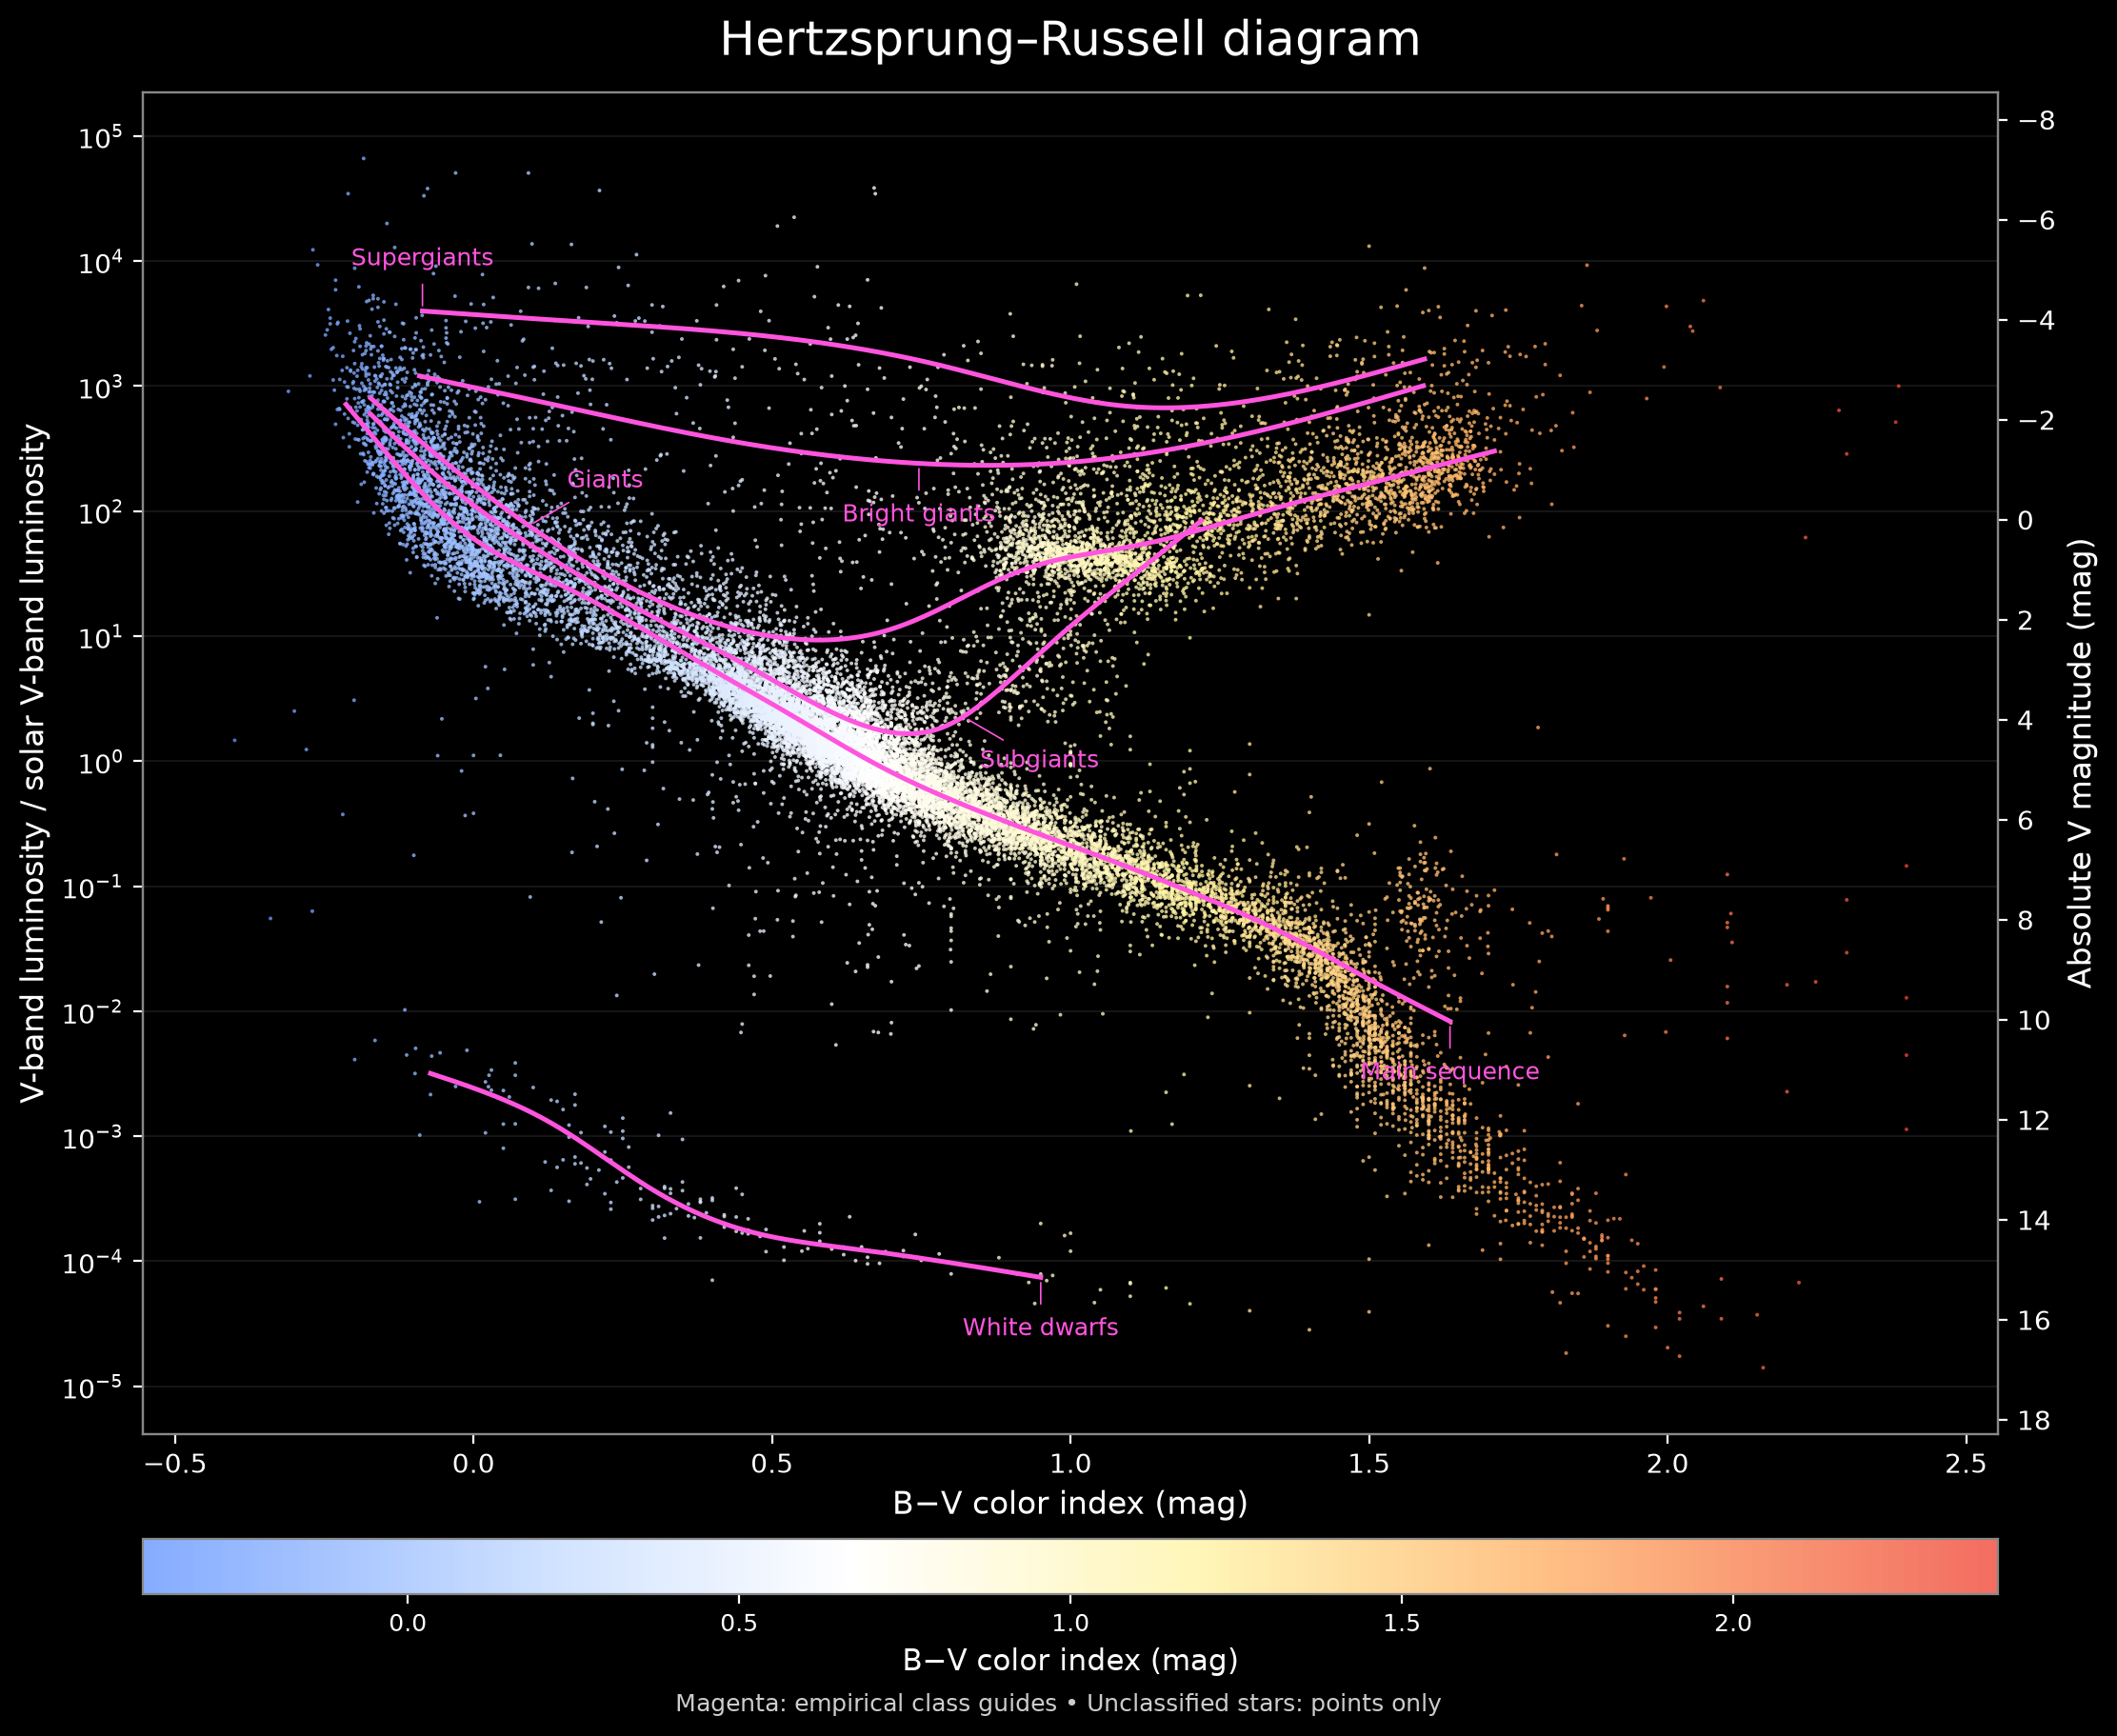

In [4]:
request = (
    "Make a classic H–R diagram on black with tiny blue–white–yellow–red stars colored "
    "by B−V, logarithmic V-band luminosity in solar units left and absolute V magnitude "
    "right, plus smooth magenta empirical guides for each classified stellar group, "
    "directly labeled over supported color ranges; exclude Unclassified from guides."
)
chart = ap.plot(
    stars, prompt=request, backend="matplotlib", max_model_calls=1,
    regenerate=True, timeout=240,
)


## Inspect the one-call result

Check that all eligible stars are visible, the two V-band brightness scales agree, and each magenta guide follows its observed class band over supported ranges. Required labels should identify the curves clearly without overlapping axes or colorbar text. Sparse observations remain in the scatter even where no trend is supported. The sample combines Ia and Ib into Supergiants, so it cannot reproduce separate canonical tracks. The reference appearance is a visual target, not evidence that empirical fits should trace identical curves.


In [5]:
from IPython.display import Code, display

print(chart.explanation)
print("Reused cached code:", chart.cache_hit)
print("Model calls:", chart.model_calls)
display(Code(chart.code, language="python"))


Plots all valid stars on black, colored from blue through white and yellow to red by B−V. Magenta empirical guides are smoothed separately for every classified group in log-luminosity space, without extrapolation; Unclassified stars remain visible but have no guide. The right-hand magnitude scale uses the solar V-magnitude zero point inferred from the supplied luminosity–magnitude pairs.
Reused cached code: False
Model calls: 1


def plot_data(data, *, title=None, figsize=None):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as ticker
    import augplot.plotting as apx

    df = data.copy()
    xcol = 'B_minus_V_color_index_mag'
    ycol = 'relative_V_band_luminosity_solar'
    mcol = 'absolute_V_magnitude_mag'
    for col in [xcol, ycol, mcol]:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    valid = np.isfinite(df[xcol]) & np.isfinite(df[ycol]) & (df[ycol] > 0)
    stars = df.loc[valid].copy()
    if stars.empty:
        raise ValueError('No finite color indices and positive luminosities are available.')
    paired = stars.loc[np.isfinite(stars[mcol])]
    if paired.empty:
        raise ValueError('Magnitude–luminosity pairs are needed to calibrate the right axis.')
    solar_magnitude = np.median(paired[mcol].to_numpy() + 2.5 * np.log10(paired[ycol].to_numpy()))

    fig = plt.figure(figsize=figsize if figsize is not None else (11, 9), facecolor='black', layout='constrained')
    gs = fig.add_gridspec(2, 1, height_ratios=[24, 1])
    ax = fig.add_subplot(gs[0])
    cax = fig.add_subplot(gs[1])
    ax.set_facecolor('black')
    cmap = plt.cm.colors.LinearSegmentedColormap.from_list(
        'stellar_bv', [(0.0, '#6395ff'), (0.22, '#c4dbff'), (0.38, '#ffffff'),
                       (0.57, '#fff4a3'), (0.76, '#ffae62'), (1.0, '#f04435')])
    points = ax.scatter(stars[xcol], stars[ycol], c=stars[xcol], cmap=cmap,
                        s=2, alpha=0.78, linewidths=0, rasterized=True, zorder=2)
    ax.set_yscale('log')
    xmin = float(stars[xcol].min())
    xmax = float(stars[xcol].max())
    xpad = max((xmax - xmin) * 0.055, 0.05)
    logy = np.log10(stars[ycol].to_numpy())
    ypad = max(float(np.ptp(logy)) * 0.055, 0.15)
    ax.set_xlim(xmin - xpad, xmax + xpad)
    ax.set_ylim(10 ** (logy.min() - ypad), 10 ** (logy.max() + ypad))
    ax.set_xlabel('B−V color index (mag)', color='white', fontsize=12)
    ax.set_ylabel('V-band luminosity / solar V-band luminosity', color='white', fontsize=12)
    ax.set_title(title if title is not None else 'Hertzsprung–Russell diagram',
                 color='white', fontsize=18, pad=14)
    ax.tick_params(colors='white', which='both', labelsize=10)
    for spine in ax.spines.values():
        spine.set_color('#888888')
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=12))
    ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext(base=10))
    ax.grid(axis='y', which='major', color='white', alpha=0.10, linewidth=0.6)

    right = ax.twinx()
    lo, hi = ax.get_ylim()
    right.set_ylim(solar_magnitude - 2.5 * np.log10(lo), solar_magnitude - 2.5 * np.log10(hi))
    right.set_ylabel('Absolute V magnitude (mag)', color='white', fontsize=12)
    right.tick_params(colors='white', labelsize=10)
    right.yaxis.set_major_locator(ticker.MultipleLocator(2))
    for spine in right.spines.values():
        spine.set_color('#888888')

    cb = fig.colorbar(points, cax=cax, orientation='horizontal')
    cb.set_label('B−V color index (mag)', color='white', fontsize=11)
    cb.ax.tick_params(colors='white', labelsize=9)
    cb.outline.set_edgecolor('#888888')

    curves = []
    classified = stars.loc[stars['stellar_class'].notna() & stars['stellar_class'].ne('Unclassified')]
    for name, group in classified.groupby('stellar_class', sort=True):
        segments = apx.smooth_trend(group[xcol].to_numpy(), np.log10(group[ycol].to_numpy()))
        if not segments:
            raise ValueError('Insufficient observations for the required guide: ' + str(name))
        for curve_x, curve_log_y in segments:
            curve_y = 10 ** np.asarray(curve_log_y)
            ax.plot(curve_x, curve_y, color='#ff55de', linewidth=1.8, zorder=4)
            curves.append((str(name), curve_x, curve_y))
    apx.label_curves(ax, curves, color='#ff55de', fontsize=9)
    fig.supxlabel('Magenta: empirical class guides • Unclassified stars: points only

## Save and reuse the chart as ordinary Python

Export the plotting function, including any used helper implementations, to `augplot_utils.py`, then call it directly on the stellar table. The exported function needs NumPy, Pandas, Matplotlib, and SciPy when smoothing is used; it needs neither Augplot nor model credentials.


In [6]:
chart.to_python(function_name="h_r_diagram")

# With '.' on your Python import path:
from augplot_utils import h_r_diagram
fig = h_r_diagram(your_data)
fig


PosixPath('augplot_utils.py')

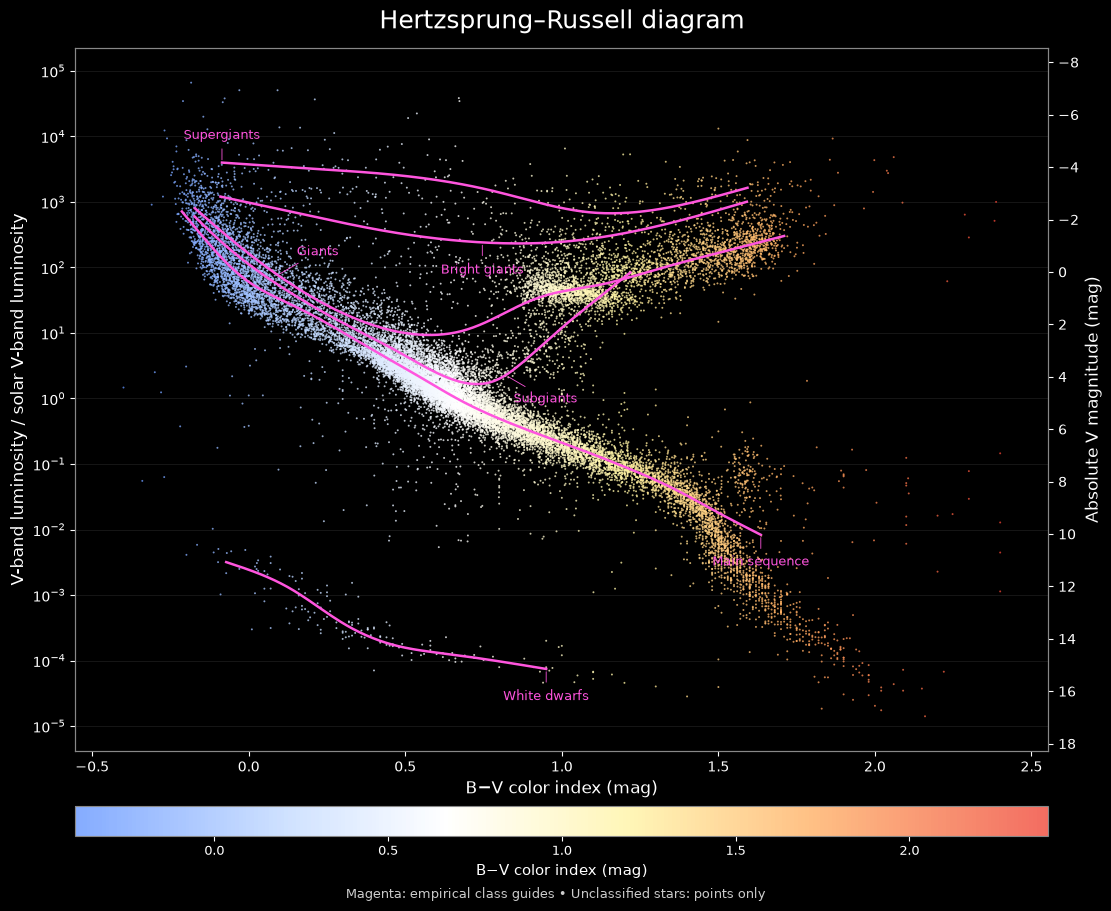

In [7]:
from augplot_utils import h_r_diagram

fig = h_r_diagram(stars)